# Decision Trees

A decision tree is a supervised machine learning algorithm used for classification and regression tasks. It works by splitting the data into subsets based on the value of input features, creating a tree-like model of decisions.

**Outcomes**:
- Use a decision tree
    - Describe how data should be transformed
    - Create a decision tree from a dataset
    - Intepret the printout of a decision tree
    - Measure the category performance of a decision tree model using accuracy, precision, and recall
    - Measure the numerical prediction performance of a decision tree model using RMSE and R^2
- Describe how to reduce overfitting with leaf size and max depth
- Describe the difference between whitebox and blackbox modeling techniques (older statistical methods v. newer machine learning)
- Explain how a test/train split can help reduce overfitting
- Explain how cross validation can help reduce overfitting
- Explain why a decision tree can use a virtually unlimited number of features without overfitting (unlike regression).

**Links**:
- Word [template](decision-tree-problem.docx) and [solution](decision-tree-key.docx) for the decision tree split problem
- [template](template.ipynb) and [affairs1](affairs.csv) and [affairs2](affairs_occupations.csv) datasets

**Resources**:
- [Decision Trees - Entropy explained](https://mlu-explain.github.io/decision-tree/)
- [Bias and variance](https://mlu-explain.github.io/bias-variance/)
- [Train and Test and Validation](https://mlu-explain.github.io/train-test-validation/)
- [Cross Validation](https://mlu-explain.github.io/cross-validation/)
- [Random Forest](https://mlu-explain.github.io/random-forest/)

## Roadmap

Use this map to follow the code blocks below. A code block often covers several stages (A–G), so match the variable names on the arrows. This page runs the pattern twice: first with a regression tree (predicting `mpg`, a number), then with a classification tree (predicting `origin`, a category). The linear regression block is the optional whitebox baseline.

![Decision tree roadmap](decision-tree-roadmap.svg)

## Overview

A decision tree is a supervised machine learning algorithm used for classification and regression tasks. It works by splitting the data into subsets based on the value of input features, creating a tree-like model of decisions.

Key Concepts:

- Trees can predict either categorical (classification) and continuous (regression) outcomes.
- Use data splitting (train/test) to evaluate the model's performance on unseen data.
- Do not scale variables in decision trees (as they are not distance-based algorithms).
- We use one-hot encoding for text variables.

Problems:

- Overfitting is a major problem with decision trees.
    - Decision trees can build very elaborate trees. In the worse case, these will perfectly memorize the training data, meaning that they may not work well on new data.
    - Techniques to prevent overfitting include pruning the tree, setting a maximum depth, or requiring a minimum number of samples per leaf node.
    - Pruning means cutting back branches that add complexity without improving predictions. Setting `max_depth` or `min_samples_leaf` stops the tree from growing those branches in the first place.

Interpretation:

- Overall model:
    - We can visualize the decision tree structure to understand the decision rules.
    - Feature importance can be assessed to see which features contribute most to the predictions.
- Individual predictions:
    - We can evaluate the model's performance using metrics like accuracy, precision, recall, F1-score for classification, or mean squared error for regression.
        - Accuracy is the share of all predictions that are correct.
        - Precision asks: of the rows the model predicted to be in a class, what share really are? If the model predicts 20 cars are from europe and 15 really are, precision is 15 / 20 = 0.75.
        - Recall asks: of the rows that really are in a class, what share did the model find? If there are 30 europe cars and the model finds 15 of them, recall is 15 / 30 = 0.50.
        - A confusion matrix shows the counts behind these numbers, with one row for each actual class and one column for each predicted class.

## Topic: Test and train data split

In contrast to a classical approach, modern machine learning practices often involve splitting the dataset into training and testing sets to evaluate model performance. In this approach, we do not evaluate individual coefficients for significance, but rather focus on overall model performance metrics. Because we are not focusing on an understandable model, we can use more complex models that may not be easily interpretable. However, this means that we need to be careful to avoid overfitting.

This is the difference between whitebox and blackbox modeling. A whitebox model, such as a linear regression or a small decision tree, can be read and explained: you can see the coefficients or follow the splits. A blackbox model, such as a very deep tree or a random forest, may predict well, but its internal reasoning is hard to interpret. Older statistical methods favor whitebox models, while newer machine learning methods often accept a blackbox in exchange for better predictions.

Key Concepts:
- The dataset is divided into two parts: the training set and the testing set. The training set is used to train the model, while the testing set is used to evaluate its performance on unseen data.
- Common splits include 70/30 or 80/20, where 70% or 80% of the data is used for training, and the remaining 30% or 20% is used for testing.
- The goal is to ensure that the model generalizes well to new data, rather than just memorizing the training data.

Interpretation:
- Measure performance on the training set. How well does our model account for the data it was trained on? If this is very low, our data may not be suitable for modeling.
- Measure performance on the test set. How well does our model perform on new, unseen data? This is typically lower than performance on the training set.
- In this approach, we typically do not interpret individual coefficients for significance. Instead, we focus on the overall predictive performance of the model.

*Cross-validation*

Cross-validation is a technique used to assess how the results of a statistical analysis will generalize to an independent dataset. It is mainly used in settings where the goal is prediction, and one wants to estimate how accurately a predictive model will perform in practice.

The basic idea of cross-validation is to partition the data into subsets, train the model on some subsets (training set), and validate it on the remaining subsets (validation set). This process is repeated multiple times to ensure that every data point has been used for both training and validation.

## Step 1: Load and Explore the Data

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

import matplotlib.pyplot as plt

df = sns.load_dataset("mpg").dropna()

# Create a new column 'make' by splitting the 'name' column and taking the first word
df['make'] = df['name'].apply(lambda x: x.split(' ')[0])

df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name,make
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu,chevrolet
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320,buick
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite,plymouth
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst,amc
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino,ford
...,...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl,ford
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup,vw
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage,dodge
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger,ford


## Step 2: Define predictors and target

In [2]:
target = 'mpg'
numeric_features = ['weight', 'horsepower', 'displacement', 'acceleration', 'cylinders']
categorical_features = [ 'origin', 'make']

X = df[numeric_features + categorical_features]
y = df[target]

# One-Hot Encode the categorical predictors
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=False)

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.25, random_state=42
)


## Step 3: Prediction of mpg (continuous value)

The decision tree regressor predicts the miles per gallon (mpg) based on the input features. It splits the data into regions with similar mpg values, allowing us to estimate the fuel efficiency of a car given its attributes.

In [3]:
# Use normal linear regression
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)
print("Linear Regression MAE:", mae_lr)
print("Linear Regression RMSE:", rmse_lr)
print("Linear Regression R^2:", r2_lr)


Linear Regression MAE: 3.4386653125824727
Linear Regression RMSE: 4.291479564241145
Linear Regression R^2: 0.6348272785373761


In [4]:
# Use a decision tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create and fit decision tree
tree = DecisionTreeRegressor(
    random_state=42,
    max_depth=3,          # limit depth for stability and interpretability
    min_samples_leaf=5
)
tree.fit(X_train, y_train)

# Predict on test set
y_pred = tree.predict(X_test)

# Calculate metrics, using mae (mean absolute error), rmse (root mean squared error), r2 (R-squared)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R^2:", r2)

# Feature importance, which is defined as the total reduction of the criterion (MSE) brought by that feature.
feature_importances = pd.DataFrame({
    'feature': X_train.columns,
    'importance': tree.feature_importances_
}).sort_values('importance', ascending=False)

feature_importances

MAE: 3.3894273250749642
RMSE: 4.441897252023425
R^2: 0.6087798210484368


,feature,importance
2,displacement,0.762519
1,horsepower,0.190945
0,weight,0.039471
18,make_datsun,0.007065
33,make_plymouth,0.000000
26,make_mercedes,0.000000
27,make_mercedes-benz,0.000000
28,make_mercury,0.000000
29,make_nissan,0.000000
30,make_oldsmobile,0.000000


## Measure accuracy on test set.



In [5]:
# Measure accuracy on test set.
y_pred = tree.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R^2:", r2)

MAE: 3.3894273250749642
RMSE: 4.441897252023425
R^2: 0.6087798210484368


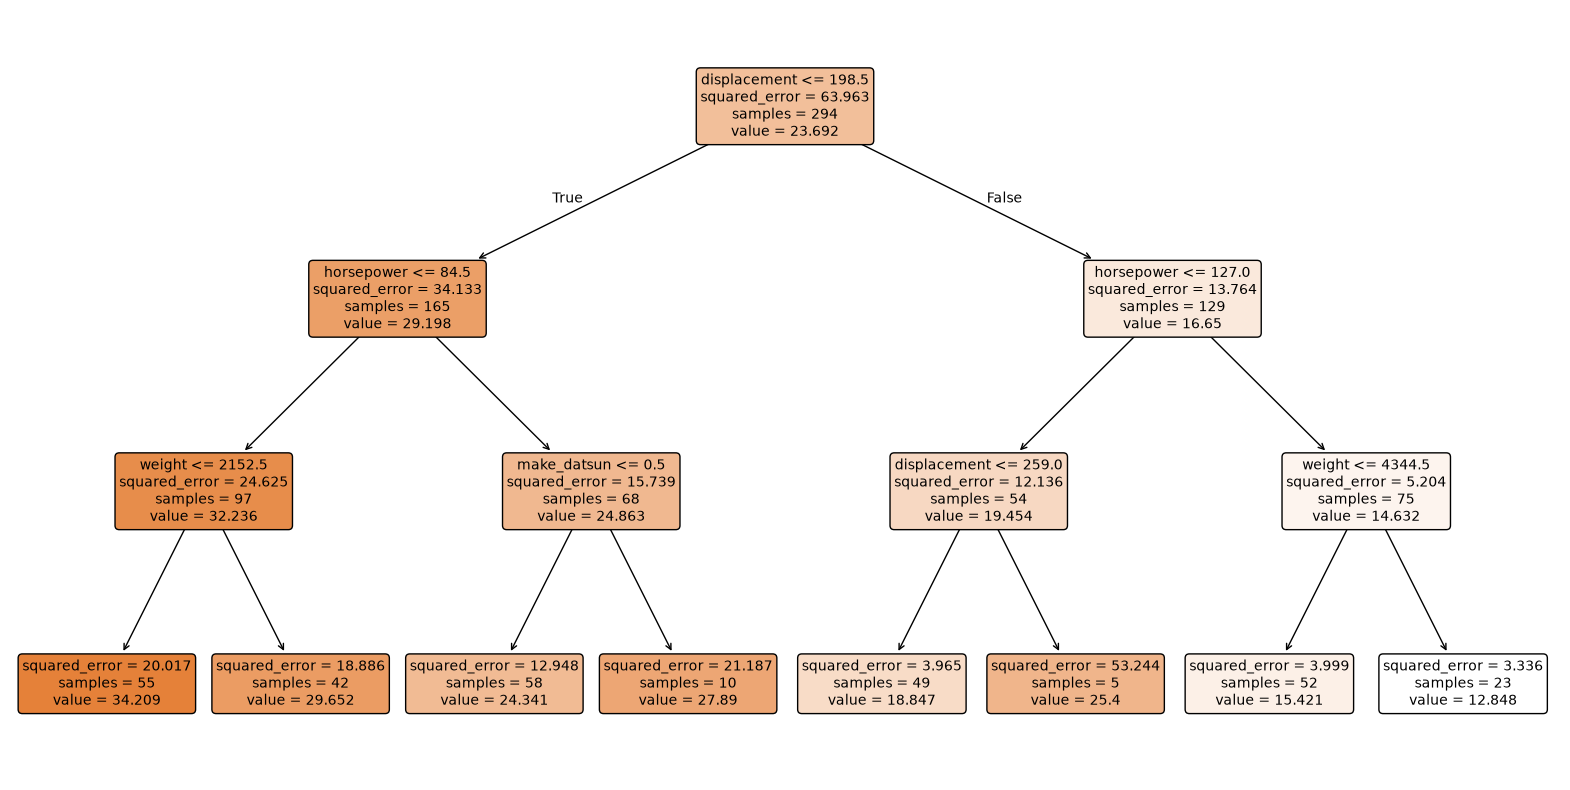

In [6]:
# Visualize tree
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))
plot_tree(tree, feature_names=X_train.columns, filled=True, rounded=True, fontsize=10)
plt.show()

## Alternative: Predict a class variable

This is used when we want to classify data points into categories based on their features. For example, we could classify cars into different fuel efficiency categories (e.g., low, medium, high) based on their attributes.

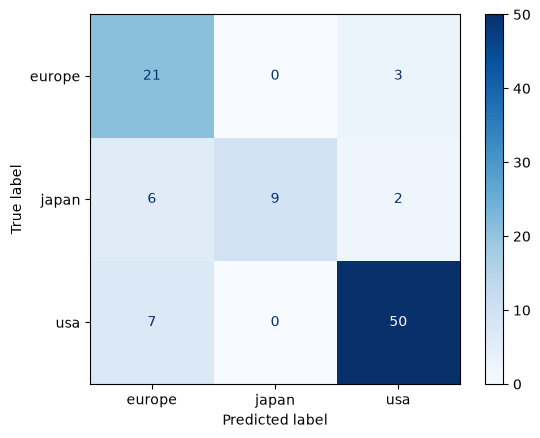

Accuracy: 0.8163265306122449
Confusion Matrix:
 [[21  0  3]
 [ 6  9  2]
 [ 7  0 50]]


In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

numeric_features = ['weight', 'horsepower', 'displacement', 'acceleration', 'cylinders', 'model_year']
categorical_features = ['make']

X = df[numeric_features + categorical_features]
y = df['origin']

# One-hot encode
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.25, random_state=42
)

clf = DecisionTreeClassifier(
    random_state=42,
    max_depth=3,
    min_samples_leaf=5
)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clf.classes_, cmap='Blues')
plt.show()


print("Accuracy:", acc)
print("Confusion Matrix:\n", cm)


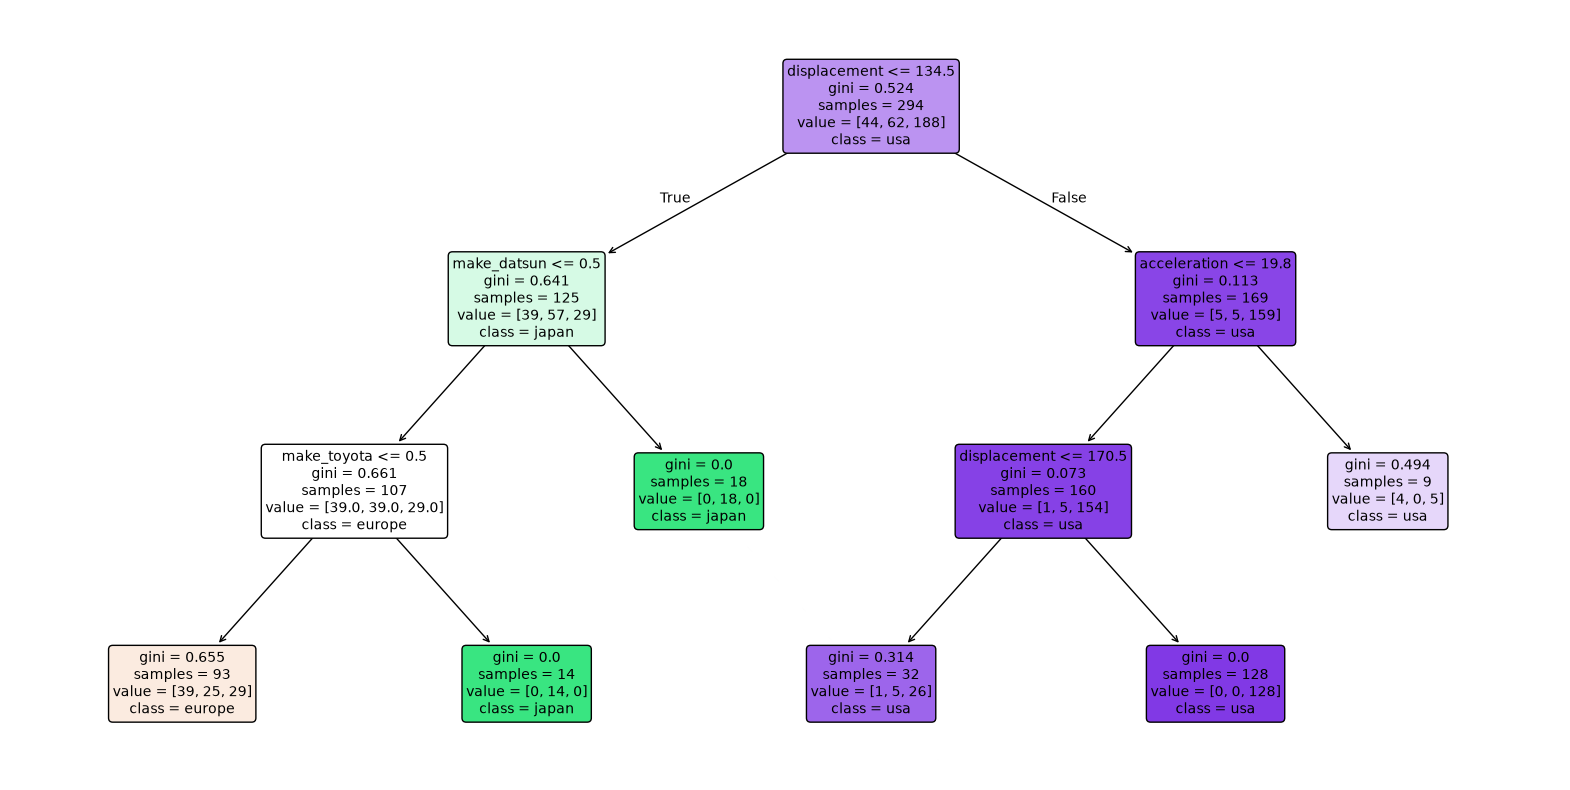

In [8]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Show decision tree. The top line shows the decision rule.
# The second line shows gini, which is defined as 1 - sum(p_i^2) for each class i, 
#   where p_i is the proportion of samples of class i at that node.
# Gini ranges from 0 (pure node) up to 1 - 1/k when k classes are evenly mixed:
#   0.5 for two classes, and about 0.67 for the three origins here.
# The line with value = ... shows the number of samples at that node.
# The last line shows the most common class distribution at that node.

plt.figure(figsize=(20,10))
plot_tree(
    clf,
    feature_names=X_train.columns,
    class_names=[str(c) for c in clf.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()

## Key Terms

- **Decision tree**: A supervised model that predicts an outcome by splitting the data into smaller groups with a series of yes/no rules
- **Classification tree**: A decision tree that predicts a category, such as a car's origin (`DecisionTreeClassifier`)
- **Regression tree**: A decision tree that predicts a continuous number, such as mpg (`DecisionTreeRegressor`)
- **Root node**: The first split at the top of the tree, which contains all of the training rows
- **Split (decision rule)**: A yes/no test on one feature, such as weight <= 2500, that divides a node into two branches
- **Leaf node**: An end point of the tree with no further splits, where the prediction is made
- **Gini impurity**: A measure of how mixed the classes are in a node, calculated as 1 minus the sum of each class proportion squared
- **Pure node**: A node where every row belongs to the same class, giving a gini of 0
- **Overfitting**: When a model memorizes the training data, including its noise, and performs poorly on new data
- **Max depth**: A limit on how many levels of splits a tree may have (`max_depth`)
- **Minimum samples per leaf**: The smallest number of training rows allowed in a leaf (`min_samples_leaf`)
- **Pruning**: Cutting back branches of a tree that add complexity without improving predictions
- **Train/test split**: Dividing the data into one part used to fit the model and another part held back to evaluate it
- **Training set**: The portion of the data, often 70% to 80%, used to fit the model
- **Test set**: The portion of the data held back and used only to measure performance on unseen data
- **Generalization**: How well a model performs on new data it was not trained on
- **Cross-validation**: Repeatedly splitting the data into training and validation parts so that every row is used for both
- **Feature importance**: A score showing how much each feature reduced error across all of the splits in the tree
- **Accuracy**: The share of all predictions that are correct
- **Confusion matrix**: A table that counts predictions by actual class and predicted class
- **Precision**: Of the rows predicted to be in a class, the share that really are in that class
- **Recall**: Of the rows that really are in a class, the share that the model found
- **MAE (mean absolute error)**: The mean size of the prediction errors, ignoring their sign
- **Whitebox model**: A model whose reasoning can be read and explained, such as a regression or a small decision tree
- **Blackbox model**: A model that predicts well but whose internal reasoning is hard to interpret


## Practice Questions

1. How does a decision tree make a prediction?
   - It follows a series of yes/no splits on the features until it reaches a leaf
   - It multiplies each feature by a coefficient and adds them up
   - It measures the distance to the nearest rows in the data
   - It groups rows without using a known outcome
1. Which kinds of outcomes can a decision tree predict?
   - Both categories (classification) and continuous numbers (regression)
   - Only categories
   - Only continuous numbers
   - Only 0/1 outcomes
1. Which scikit-learn class would you use to predict `mpg`, a continuous number?
   - `DecisionTreeRegressor`
   - `DecisionTreeClassifier`
   - `OneHotEncoder`
   - `train_test_split`
1. In a regression tree, what value does a leaf predict?
   - The average outcome of the training rows that landed in that leaf
   - The most common class in that leaf
   - The largest outcome in that leaf
   - The outcome of the first row in that leaf
1. What is the root node of a decision tree?
   - The first split at the top, which contains all of the training rows
   - The final node where a prediction is made
   - The node with the fewest rows
   - The feature with the lowest importance
1. Why do decision trees not require scaling the numeric features?
   - They are not distance-based; each split only compares one feature to a cutoff
   - Scaling is done automatically by `get_dummies`
   - Trees only accept values between 0 and 1
   - Scaling would remove the outliers that trees depend on
1. How do we prepare a text column such as `make` for a decision tree?
   - One-hot encode it into 1/0 columns with `pd.get_dummies`
   - Leave it as text; scikit-learn trees read text directly
   - Drop every row that contains text
   - Convert each make to its alphabetical rank
1. What does overfitting mean for a decision tree?
   - The tree grows so elaborate that it memorizes the training data and does poorly on new data
   - The tree has too few splits to capture the pattern
   - The tree uses too many rows for testing
   - The tree cannot handle categorical features
1. Which settings help reduce overfitting in a decision tree?
   - Limiting `max_depth` and raising `min_samples_leaf`
   - Removing the test set
   - Scaling all of the numeric features
   - Letting the tree grow until every leaf is pure
1. What does `min_samples_leaf=5` do?
   - Prevents any split that would leave a leaf with fewer than 5 training rows
   - Limits the tree to 5 leaves
   - Limits the tree to 5 levels of splits
   - Uses only 5 features
1. Why do we split the data into training and test sets?
   - To measure how well the model performs on data it has not seen
   - To make the model train faster
   - To remove rows with missing values
   - To calculate p-values for each feature
1. The mpg dataset has 392 rows and we use `test_size=0.25`. About how many rows are in the test set?
   - 98
   - 25
   - 294
   - 196
1. A tree has an R² of 0.99 on the training set but 0.55 on the test set. What does this suggest?
   - The tree is overfit and has memorized the training data
   - The tree is too simple
   - The test set is too large
   - The model generalizes very well
1. In the test/train approach, what do we focus on instead of coefficient p-values?
   - Overall predictive performance on the test set
   - The significance of each individual feature
   - The intercept of the model
   - The number of rows in the training set
1. What is the basic idea of cross-validation?
   - Split the data into subsets and repeat training and validation so every row is used for both
   - Train the model once on all of the data and test it on the same data
   - Remove the features with the lowest importance
   - Run the model on two different datasets and compare the results
1. A node contains 8 usa cars and 2 japan cars. What is its gini impurity?
   - 0.32, because 1 - (0.8² + 0.2²)
   - 0.20
   - 0.80
   - 0
1. What is the gini impurity of a node where every row belongs to the same class?
   - 0, the node is pure
   - 0.5
   - 1
   - It cannot be calculated
1. What does feature importance tell you?
   - Which features contributed most to reducing error across the tree's splits
   - Whether a feature raises or lowers the prediction
   - The p-value of each feature
   - How many missing values each feature has
1. A model predicts 10 cars are from japan, and 8 of them really are. What is the precision for japan?
   - 0.80, because 8 of the 10 predicted are correct
   - 0.20
   - 8
   - It cannot be found without the recall
1. There are 20 japan cars in the test set and the model correctly identifies 8 of them. What is the recall for japan?
   - 0.40, because it found 8 of the 20 actual japan cars
   - 0.80
   - 0.60
   - 12
1. What does a confusion matrix show?
   - Counts of predictions broken down by actual class and predicted class
   - The correlation between each pair of features
   - The importance of each feature
   - The splits used at each level of the tree
1. What is the difference between a whitebox and a blackbox model?
   - A whitebox model's reasoning can be read and explained; a blackbox model predicts without an easily interpretable explanation
   - A whitebox model uses a test set; a blackbox model does not
   - A whitebox model predicts categories; a blackbox model predicts numbers
   - A whitebox model is always more accurate than a blackbox model